# 02 · Elo Baseline Model

Builds a baseline Elo rating for every NFL team, updated game by game and regressed toward the mean each offseason. All settings live in Section 0, so the model runs for any range of seasons. The output is a pre-game win probability for every game, scored against actual results.

In [2]:
# =============================
# Section 0: setup & parameters
# =============================

# Timeframe
FIRST_SEASON = 2005
LAST_SEASON = 2025
SCORE_FROM = 2013
TRAIN_SEASONS = range(2013, 2022)
TEST_SEASONS = range(2022, 2026)

# Model parameters
params = {
    "base": 1500,
    "scale": 400, 
    "k": 20,
    "hfa": 48,
    "season_regression": 1/3,
    "use_mov": True,
    "mov_scale": 2.2,
    "mov_slope": 0.001,
    "tie_value": 0.5,
    "neutral_hfa": 0,
    "include_playoffs": True,
    "spread_divisor": 25
}

# Franchise map
FRANCHISE_MAP = {"OAK": "LV", "SD": "LAC", "STL": "LA"}

In [3]:
# =============================
# Section 1: load & clean
# =============================

import numpy as np
import pandas as pd
import nflreadpy as nfl

KEEP_COLS = ["game_id", "season", "week", "game_type", "gameday", "gametime",
             "home_team", "away_team", "location", "home_score", "away_score"]

def load_games(first_season, last_season, tie_value):
    """
    Goal: return a clean DataFrame with one row per game, sorted in kickoff order, and ready for Elo ratings

    first_season:   the first year of data contained in the df
    last_season:    the last year of data contained in the df
    """

    # 1. Pull nfl data from the nflreadpy library
    raw = nfl.load_schedules(list(range(first_season, last_season + 1))).to_pandas()

    # 2. Keep only the necessary columns of data
    games = raw[KEEP_COLS].copy()

    # 3. Franchise mapping
    games["home_team"]= games["home_team"].replace(FRANCHISE_MAP)
    games["away_team"] = games["away_team"].replace(FRANCHISE_MAP)    

    # 4. Kickoff 
    games["kickoff"] = pd.to_datetime(games["gameday"] + " " + games["gametime"])

    # 5. Flags
    games["is_playoff"] = games["game_type"] != "REG"
    games["is_neutral"] = games["location"] == "Neutral"

    # 6. Outcomes
    games["result"] = games["home_score"] - games["away_score"]

    conditions = [games["result"] > 0,
                  games["result"] == 0,
                  games["result"] < 0]
    choices = [1.0, tie_value, 0.0]
    games["home_win"] = np.select(conditions, choices, default=np.nan)

    # 7. Sort
    games = games.sort_values(["kickoff", "game_id"]).reset_index(drop=True)

    return games

In [4]:
# =============================
# Section 2: elo math
# =============================

def elo_diff(rating_home, rating_away, hfa):
    """
    Home team's Elo advantage, including home field
    
    rating_home: home team's Elo rating before the game
    rating_away: away team's Elo rating before the game
    hfa:         home-feild advantage in Elo points (0 at neutral sites)
    """
    d = rating_home - rating_away + hfa
    return d

def home_win_prob(d, scale):
    """
    Probability the home team wins
    
    d:      home team's Elo advantage, from elo_diff
    scale:  Elo points that make 10-to-1 odds (400 byu convention)
    """
    home_prob = 1 / (1 + 10 ** (-d / scale))
    return home_prob

def predicted_spread(d, spread_divisor):
    """ 
    Expected home margin in points

    d:              home team's Elo advantage, from elo_diff
    spread_divisor: Elo points per point of spread (25 convention)    
    """
    spread = d / spread_divisor
    return spread

def mov_multiplier(margin, d_winner, use_mov, mov_scale, mov_slope):
    """ 
    Scales the rating update by margin of victory

    margin:         home score minus away score
    d_winner:       winner's Elo advantage(d if home won, -d if away won)
    use_mov:        True to apply the multiplier, False to return 1
    mov_scale:      constant that sets the size of the favorite correction (2.2 convention)
    mov_slope:      how strongly the winner's Elo advantage shrinks the multiplier (0.001 convention)
    """
    if margin == 0:
        return 1.0
    if not use_mov:
        return 1.0
    multiplier = np.log(abs(margin) + 1) * mov_scale / (mov_slope * d_winner + mov_scale)
    return multiplier

def rating_change(k, multiplier, outcome, expected):
    """ 
    Elo points the home team gains (away team loses the same amount)
    
    k:          base update size (20 convention)
    multiplier: margin of victory scaling, from mov_multiplier
    outcome:    home result (1 win, 0.5 tie, 0 loss)
    expected:   home win probability, from home_win_prob
    """
    change = k * multiplier * (outcome - expected)
    return change

def regress_ratings(ratings, frac, base):
    """ 
    Pull every rating part out of the way back toward base
    
    ratings:    dictionary of team's Elo ratings {team: elo rating}
    frac:       fraction of the gap to close (1/3 convention)
    base:       league-average rating to pull toward (1500 convention)
    """
    new_ratings = {team: r + frac * (base - r) for team, r in ratings.items()}
    return new_ratings


In [5]:
# =============================
# Section 3: elo engine
# =============================

def run_elo(games, params):
    """
    Run Elo through every game in kickoff order.

    games:  DataFrame from load_games, sorted by kickoff and game_id
    params: model parameter dictionary from Section 0

    Returns games with added columns:
    elo_home_pre, elo_away_pre, home_prob, elo_home_post, elo_away_post
    """

    # Drop playoff games if params states this
    if not params["include_playoffs"]:
        games = games[~games["is_playoff"]]

    ratings = {}                # team -> current Elo, the engine's memory
    current_season = None       # tracks when a new season starts
    results = []                # one dict per game, turned into columns at the end

    for g in games.itertuples(index=False):

        # 1. New season -> regress (skip for the first season as all teams start at 1500)
        if g.season != current_season:
            if current_season is not None:
                ratings = regress_ratings(ratings, params["season_regression"], params["base"])
            current_season = g.season

        # 2. Look up pre-game ratings (new teams start at base)
        r_home = ratings.get(g.home_team, params["base"])
        r_away = ratings.get(g.away_team, params["base"])

        # 3. Prediction
        hfa = params["neutral_hfa"] if g.is_neutral else params["hfa"]
        d = elo_diff(r_home, r_away, hfa)
        p_home = home_win_prob(d, params["scale"])

        # 4. Update only if game has been played
        r_home_post = r_home
        r_away_post = r_away
        if not pd.isna(g.home_win):
            d_winner = d if g.home_win >= 0.5 else -d
            mult = mov_multiplier(g.result, d_winner, params["use_mov"], params["mov_scale"], params["mov_slope"])
            change = rating_change(params["k"], mult, g.home_win, p_home)
            r_home_post = r_home + change
            r_away_post = r_away - change
            ratings[g.home_team] = r_home_post
            ratings[g.away_team] = r_away_post

        # 5. Save this game's numbers
        results.append({
            "elo_home_pre": r_home, 
            "elo_away_pre": r_away,
            "home_prob": p_home,
            "elo_home_post": r_home_post,
            "elo_away_post": r_away_post,
                        })
    out = pd.concat([games.reset_index(drop=True), pd.DataFrame(results)], axis=1)
    return out

In [6]:
# =============================
# Section 4: reshape
# =============================

def team_history(elo):
    """
    One row per team per game.

    elo: DataFrame returned by run_elo

    Returns columns: season, week, kickoff, team, opponent, elo_pre, elo_post
    """
    home = elo[["season", "week", "kickoff", "home_team", "away_team",
                "elo_home_pre", "elo_home_post"]].copy()
    home.columns = ["season", "week", "kickoff", "team", "opponent", "elo_pre", "elo_post"]

    away = elo[["season", "week", "kickoff", "away_team", "home_team", 
                "elo_away_pre", "elo_away_post"]].copy()
    away.columns = ["season", "week", "kickoff", "team", "opponent", "elo_pre", "elo_post"]

    history = pd.concat([home, away]).sort_values(["team", "kickoff"]).reset_index(drop=True)
    return history


def ratings_table(history, value):
    """
    Wide table: rows are (season, week), columns are teams.

    history: DataFrame from team_history
    value:   "elo_pre" or "elo_post"
    """
    table = history.pivot(index = ["season", "week"], columns = "team", values = value)
    table = table.ffill()
    return table

<Axes: xlabel='season,week'>

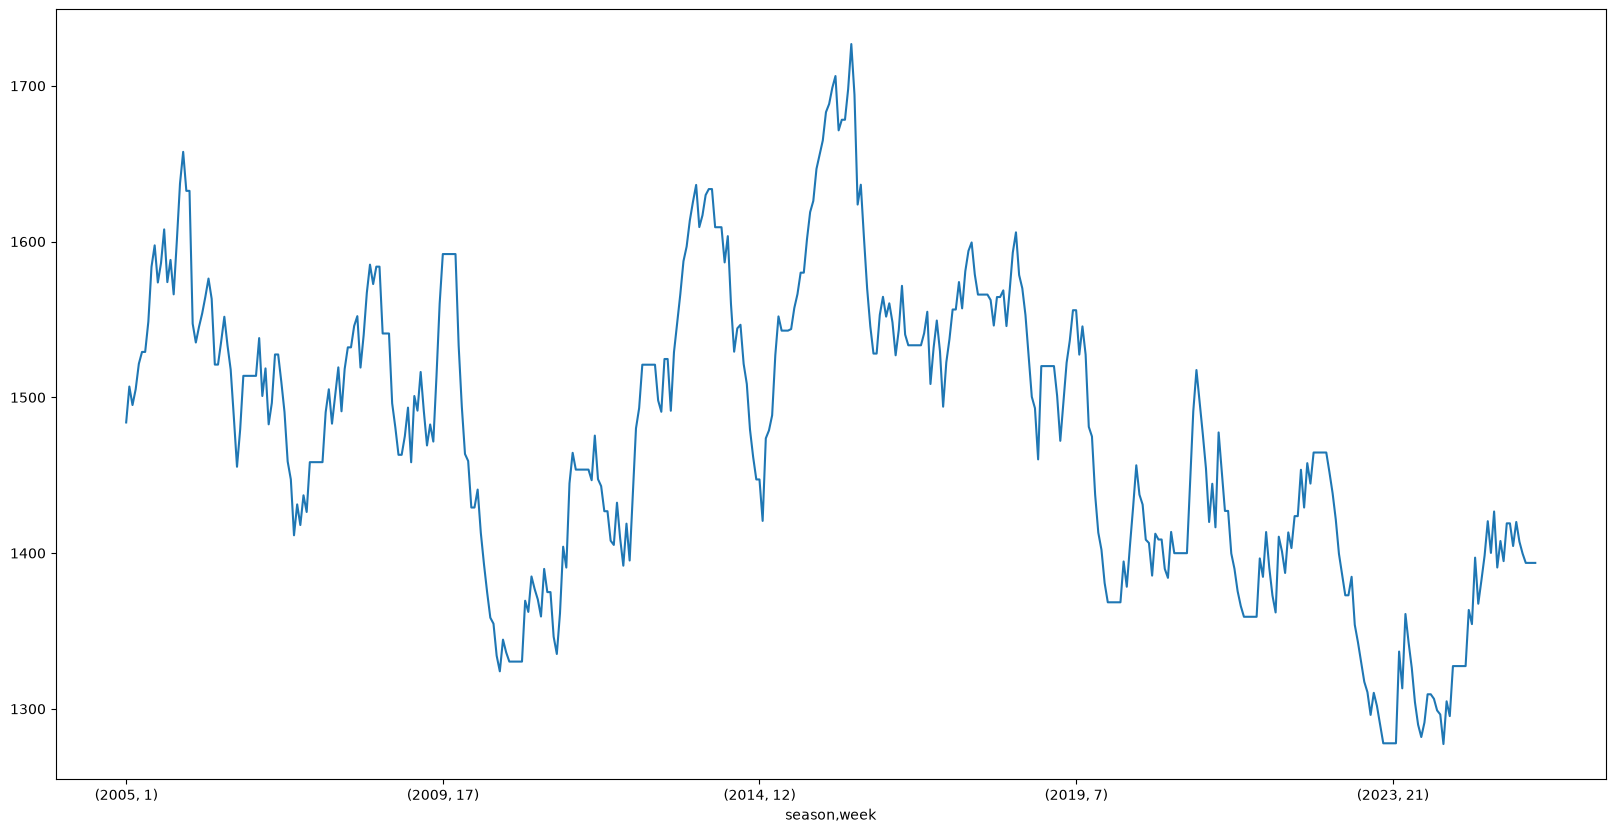

In [7]:
games = load_games(FIRST_SEASON, LAST_SEASON, params["tie_value"])
elo = run_elo(games, params)
history = team_history(elo)
ratings = ratings_table(history, "elo_post")
ratings["CAR"].plot(figsize=(20,10))

In [24]:
def check_rate(elo):
    """
    Adds a 'correct' column: True when the Elo favorite won.

    elo: DataFrame from run_elo
    """
    played = elo[(elo["result"] != 0) & elo["result"].notna()].copy()

    home_fav = played["home_prob"] > 0.5      # True where Elo picked the home team
    home_won = played["result"] > 0           # True where the home team won

    # HINT: the pick is correct when these two columns agree
    played["correct"] = home_fav == home_won
    return played

checked = check_rate(elo)

print(checked.groupby("home_team")["correct"].mean())
print(f"\nModel Accuracy: {checked.loc[checked["season"] >= SCORE_FROM, "correct"].mean()}")


home_team
ARI    0.578035
ATL    0.613636
BAL    0.703911
BUF    0.688889
CAR    0.590909
CHI    0.698324
CIN    0.597701
CLE    0.617647
DAL    0.607955
DEN    0.608696
DET    0.722543
GB     0.700000
HOU    0.657303
IND    0.651934
JAX    0.632184
KC     0.678947
LA     0.602273
LAC    0.651429
LV     0.602339
MIA    0.604651
MIN    0.645714
NE     0.766497
NO     0.600000
NYG    0.616279
NYJ    0.625731
PHI    0.666667
PIT    0.662983
SEA    0.717391
SF     0.659218
TB     0.629213
TEN    0.655172
WAS    0.578035
Name: correct, dtype: float64

Model Accuracy: 0.6476056338028169


In [ ]:
# =============================
# Section 5: brier score
# =============================